# Geometrie und Trigonometrie

## 04 - Anwendungen der Trigonometrie

Vermessung (Höhen mit $\tan$, Entfernungen über zwei Winkel mit Sinussatz), Schwingungen ($y(t) = A \cdot \sin(\omega t + \varphi)$: Amplitude $A$, Kreisfrequenz $\omega$, Phase $\varphi$) und Vektorzerlegung von Kräften.

> Vorausgesetzt: Sinus/Cosinus, Sinussatz, Kosinussatz (04_Trigonometrie/01-03).

### Lernziele

- Du kannst **Höhen und Entfernungen** mit Trigonometrie berechnen (Vermessung).
- Du verstehst **Schwingungen** als Sinusfunktionen ($y = A \sin(\omega t + \varphi)$).
- Du kannst eine Kraft in **Komponenten** zerlegen (Vektorzerlegung).

---

## 1. Vermessung: Höhen und Entfernungen

### Höhe eines Objekts

Stehst du in Entfernung $d$ von einem Objekt und misst den **Elevationswinkel** $\alpha$ (von der Horizontalen nach oben), dann gilt:

$$h = d \cdot \tan(\alpha)$$

(wobei $h$ ab deiner Augenhöhe gemessen wird.)

### Entfernung über zwei Winkel

Misst du von zwei Standpunkten $A$ und $B$ (Abstand $d$ bekannt) die Winkel $\alpha$ und $\beta$ zum Zielpunkt $C$, kannst du mit dem **Sinussatz** alle fehlenden Größen berechnen.

### Beispiel

Du stehst $50\text{ m}$ von einem Turm entfernt und misst einen Elevationswinkel von $35°$.  
Deine Augenhöhe ist $1{,}7\text{ m}$.

$$h_{\text{Turm}} = 50 \cdot \tan(35°) + 1{,}7 \approx 50 \cdot 0{,}7002 + 1{,}7 \approx 36{,}7\text{ m}$$

## 2. Schwingungen und Wellen

Viele periodische Vorgänge lassen sich als Sinusfunktion beschreiben:

$$y(t) = A \cdot \sin(\omega t + \varphi)$$

| Parameter | Bedeutung | Einheit |
|---|---|---|
| $A$ | **Amplitude** — maximale Auslenkung | je nach Kontext (m, V, …) |
| $\omega = \frac{2\pi}{T} = 2\pi f$ | **Kreisfrequenz** | rad/s |
| $T$ | **Periode** — Dauer einer Schwingung | s |
| $f = \frac{1}{T}$ | **Frequenz** — Schwingungen pro Sekunde | Hz |
| $\varphi$ | **Phase** — horizontale Verschiebung | rad |

### Beispiel: Wechselstrom

Europäische Netzspannung: $U(t) = 325 \cdot \sin(2\pi \cdot 50 \cdot t)$

- Amplitude: $A = 325\text{ V}$ (Spitzenwert)
- Frequenz: $f = 50\text{ Hz}$
- Periode: $T = \frac{1}{50} = 0{,}02\text{ s}$

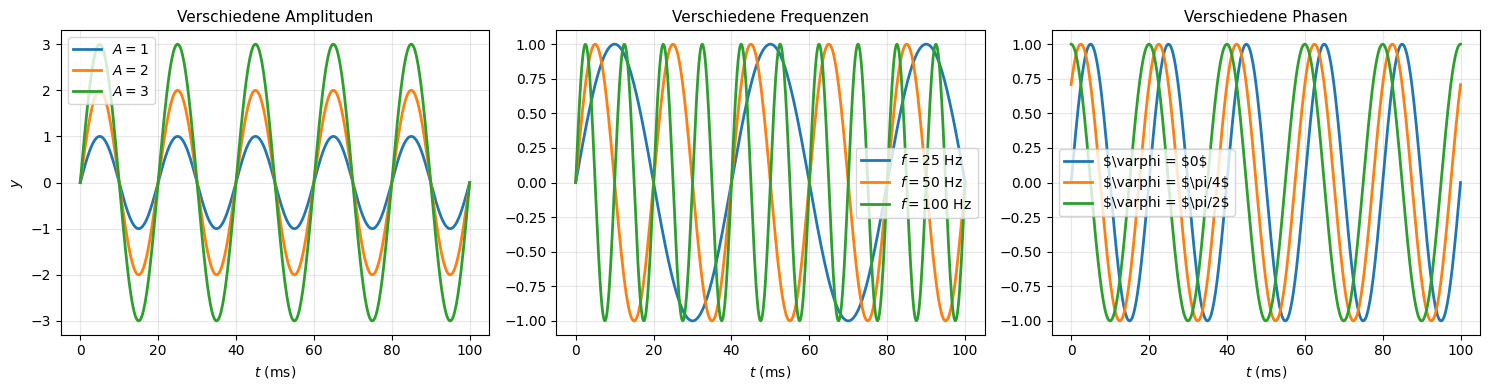

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Visualisierung: Schwingungen mit verschiedenen Parametern ---

t = np.linspace(0, 0.1, 500)  # 0 bis 0.1 Sekunden

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- 1. Amplitudenvergleich ---
ax = axes[0]
for A in [1, 2, 3]:
    ax.plot(t * 1000, A * np.sin(2 * np.pi * 50 * t), linewidth=2, label=f'$A = {A}$')
ax.set_xlabel('$t$ (ms)')
ax.set_ylabel('$y$')
ax.set_title('Verschiedene Amplituden', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# --- 2. Frequenzvergleich ---
ax = axes[1]
for f in [25, 50, 100]:
    ax.plot(t * 1000, np.sin(2 * np.pi * f * t), linewidth=2, label=f'$f = {f}$ Hz')
ax.set_xlabel('$t$ (ms)')
ax.set_title('Verschiedene Frequenzen', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# --- 3. Phasenverschiebung ---
ax = axes[2]
for phi_label, phi in [('$0$', 0), ('$\\pi/4$', np.pi/4), ('$\\pi/2$', np.pi/2)]:
    ax.plot(t * 1000, np.sin(2 * np.pi * 50 * t + phi), linewidth=2, label=f'$\\varphi = {phi_label}')
ax.set_xlabel('$t$ (ms)')
ax.set_title('Verschiedene Phasen', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Kräftezerlegung (Vektorzerlegung)

Eine Kraft $\vec F$, die unter einem Winkel $\alpha$ zur Horizontalen wirkt, kann in zwei **Komponenten** zerlegt werden:

- **Horizontale Komponente:** $F_x = F \cdot \cos(\alpha)$
- **Vertikale Komponente:** $F_y = F \cdot \sin(\alpha)$

### Beispiel: Schiefe Ebene

Ein Block ($m = 10\text{ kg}$) liegt auf einer schiefen Ebene mit Neigungswinkel $30°$.  
Die Gewichtskraft ist $F_G = m \cdot g = 98{,}1\text{ N}$ (senkrecht nach unten).

Zerlegung relativ zur Ebene:
- **Hangabtriebskraft** (parallel zur Ebene): $F_{\parallel} = F_G \cdot \sin(30°) = 49{,}05\text{ N}$
- **Normalkraft** (senkrecht zur Ebene): $F_{\perp} = F_G \cdot \cos(30°) \approx 84{,}96\text{ N}$

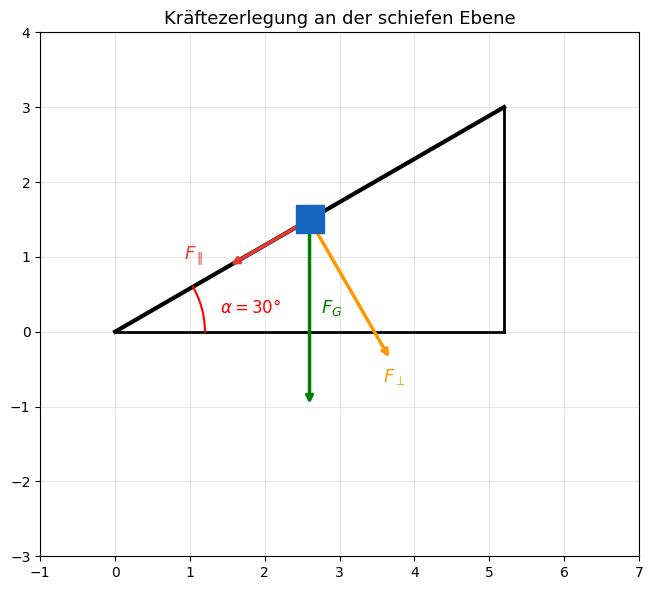

In [3]:
# --- Visualisierung: Schiefe Ebene und Kräftezerlegung ---

import math

fig, ax = plt.subplots(figsize=(9, 6))

alpha_deg = 30
alpha = math.radians(alpha_deg)
L = 6  # Länge der Rampe

# Schiefe Ebene zeichnen
rampe_x = [0, L * math.cos(alpha)]
rampe_y = [0, L * math.sin(alpha)]
ax.plot(rampe_x, rampe_y, 'k-', linewidth=3)
ax.plot([rampe_x[1], rampe_x[1]], [0, rampe_y[1]], 'k-', linewidth=2)
ax.plot([0, rampe_x[1]], [0, 0], 'k-', linewidth=2)

# Block-Position (Mitte der Rampe)
bx = 0.5 * L * math.cos(alpha)
by = 0.5 * L * math.sin(alpha)
ax.plot(bx, by, 's', color='#1565C0', markersize=20, zorder=5)

# Gewichtskraft (nach unten)
Fg = 2.5
ax.annotate('', xy=(bx, by - Fg), xytext=(bx, by),
            arrowprops=dict(arrowstyle='->', color='green', lw=2.5))
ax.text(bx + 0.15, by - Fg / 2, '$F_G$', fontsize=13, color='green')

# Hangabtriebskraft (parallel zur Ebene, nach unten)
F_par = Fg * math.sin(alpha)
dx_par = -F_par * math.cos(alpha)
dy_par = -F_par * math.sin(alpha)
ax.annotate('', xy=(bx + dx_par, by + dy_par), xytext=(bx, by),
            arrowprops=dict(arrowstyle='->', color='#E53935', lw=2.5))
ax.text(bx + dx_par - 0.6, by + dy_par + 0.1, '$F_{\\parallel}$', fontsize=13, color='#E53935')

# Normalkraft (senkrecht zur Ebene, nach innen)
F_perp = Fg * math.cos(alpha)
dx_perp = -F_perp * math.sin(alpha)
dy_perp = F_perp * math.cos(alpha)
ax.annotate('', xy=(bx - dx_perp, by - dy_perp), xytext=(bx, by),
            arrowprops=dict(arrowstyle='->', color='#FF9800', lw=2.5))
ax.text(bx - dx_perp - 0.1, by - dy_perp - 0.3, '$F_{\\perp}$', fontsize=13, color='#FF9800')

# Winkelbogen
bogen = np.linspace(0, alpha, 30)
r = 1.2
ax.plot(r * np.cos(bogen), r * np.sin(bogen), 'r-', linewidth=1.5)
ax.text(1.4, 0.25, f'$\\alpha = {alpha_deg}°$', fontsize=12, color='red')

ax.set_xlim(-1, 7)
ax.set_ylim(-3, 4)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title('Kräftezerlegung an der schiefen Ebene', fontsize=13)

plt.tight_layout()
plt.show()

---

## Verständnis-Check

**Aufgabe 1: Vermessung**

Du stehst $80\text{ m}$ von einem Gebäude entfernt und misst einen Elevationswinkel von $28°$. Deine Augenhöhe beträgt $1{,}65\text{ m}$.

Wie hoch ist das Gebäude?

**Aufgabe 2: Schwingung ablesen**

Gegeben: $y(t) = 3 \cdot \sin(100\pi t + \frac{\pi}{6})$

a) Bestimme Amplitude, Frequenz und Periode.

b) Was ist der Funktionswert bei $t = 0$?

**Aufgabe 3: Kräftezerlegung**

Ein Seil zieht mit $F = 200\text{ N}$ unter einem Winkel von $40°$ zur Horizontalen an einem Schlitten.

a) Wie groß ist die horizontale Zugkraft $F_x$?

b) Wie groß ist die vertikale Kraft $F_y$?

### Lösungen

<details><summary>Lösung Aufgabe 1</summary>

$$h = d \cdot \tan(\alpha) + h_{\text{Auge}} = 80 \cdot \tan(28°) + 1{,}65$$
$$h = 80 \cdot 0{,}5317 + 1{,}65 = 42{,}54 + 1{,}65 \approx 44{,}19\text{ m}$$

</details>

<details><summary>Lösung Aufgabe 2</summary>

a) Amplitude $A = 3$, $\omega = 100\pi$

$$f = \frac{\omega}{2\pi} = \frac{100\pi}{2\pi} = 50\text{ Hz}, \quad T = \frac{1}{f} = 0{,}02\text{ s} = 20\text{ ms}$$

b) $y(0) = 3 \cdot \sin\!\left(\frac{\pi}{6}\right) = 3 \cdot 0{,}5 = 1{,}5$

</details>

<details><summary>Lösung Aufgabe 3</summary>

a) $F_x = F \cdot \cos(\alpha) = 200 \cdot \cos(40°) = 200 \cdot 0{,}7660 \approx 153{,}21\text{ N}$

b) $F_y = F \cdot \sin(\alpha) = 200 \cdot \sin(40°) = 200 \cdot 0{,}6428 \approx 128{,}56\text{ N}$

</details>

## Zusammenfassung

| Thema | Kernaussage |
|:------|:------------|
| **Vermessung** | Höhen und Entfernungen über $\tan(\alpha)$ und bekannte Abstände berechnen |
| **Schwingungen** | $y(t) = A\sin(\omega t + \varphi)$ — Amplitude, Frequenz $f = \frac{\omega}{2\pi}$, Periode $T = \frac{1}{f}$ |
| **Kräftezerlegung** | $F_x = F\cos(\alpha)$, $F_y = F\sin(\alpha)$ — Projektion auf Achsen |



---

## Glossar

| Deutsch | English |
|---------|---------|
| Vermessung | Surveying |
| Elevationswinkel | Angle of elevation |
| Schwingung | Oscillation |
| Amplitude | Amplitude |
| Frequenz | Frequency |
| Periode | Period |
| Kreisfrequenz | Angular frequency |
| Phase / Phasenverschiebung | Phase / phase shift |
| Kräftezerlegung | Force decomposition |
| Schiefe Ebene | Inclined plane |
| Hangabtriebskraft | Downhill force component |